# **1. BAYES CLASSIFIER (Multinomial Naïve Bayes)**
---

### **1. Thiết lập môi trường và nạp dữ liệu MNIST đã tiền xử lý**


Naïve Bayes dự đoán lớp bằng cách kết hợp xác suất của dữ liệu khi biết lớp với xác suất ban đầu của lớp. Với **Multinomial Naïve Bayes**, mỗi đặc trưng được xem như một lượng không âm; mô hình dùng các giá trị này để ước lượng phân bố đặc trưng theo từng lớp. Vì vậy, dữ liệu Z-score có thể âm sẽ không phù hợp với giả định của mô hình. Ta dùng Min-Max `[0, 1]` để giữ cường độ pixel không âm và bảo toàn mức độ sáng tương đối của ảnh.


Kế thừa kết quả tiền xử lý từ `0_Preprocessing_EDA.ipynb`:
* Lấy trực tiếp dữ liệu chuẩn hoá dạng **MinMax $[0, 1]$** (`X_train_minmax`, `X_val_minmax`, `X_test_minmax`). Dữ liệu không âm mô hình hóa tự nhiên lượng mực trên từng pixel.
* Đảm bảo tập Train ($50.000$ mẫu) học tham số, tập Validation ($10.000$ mẫu) chọn siêu tham số $\alpha$, và tập Test ($10.000$ mẫu) độc lập chỉ đánh giá đúng 1 lần duy nhất.

In [26]:
import os
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [27]:
# 0. Xác định thư mục gốc dự án và thêm src vào sys.path
try:
    from IPython.display import display
except ImportError:
    display = print

# 1. Xác định PROJECT_ROOT dựa vào pyproject.toml
PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "pyproject.toml").is_file() and (PROJECT_ROOT / "src" / "pattern_recognition" / "config.py").is_file()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (chứa pyproject.toml).")
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_PATH = str(PROJECT_ROOT / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

# 2. Khởi tạo các thư mục lưu trữ của đồ án
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
for output_dir in (FIGURES_DIR, RESULTS_DIR, ARTIFACTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

# 3. Cố định tính tái lập ngẫu nhiên từ cấu hình chung
from pattern_recognition.config import SEED
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
print(f"Thiết lập môi trường thành công! SEED cố định = {SEED}")


Thiết lập môi trường thành công! SEED cố định = 42


In [28]:
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "mnist_processed.npz"
data = np.load(DATA_PATH)
X_train = data["X_train_minmax"]  
y_train = data["y_train"]        
X_val   = data["X_val_minmax"]   
y_val   = data["y_val"]           
X_test  = data["X_test_minmax"]   
y_test  = data["y_test"]         

# Kiểm tra kích thước và miền giá trị của từng tập dữ liệu.
print(f"Nạp dữ liệu thành công từ: '{DATA_PATH.name}'")
print(f"  - Tập Huấn luyện (Train)     : X = {tuple(X_train.shape)} | y = {tuple(y_train.shape)} | Miền giá trị: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"  - Tập Kiểm định  (Validation): X = {tuple(X_val.shape)}   | y = {tuple(y_val.shape)}   | Miền giá trị: [{X_val.min():.2f}, {X_val.max():.2f}]")
print(f"  - Tập Kiểm thử   (Test)      : X = {tuple(X_test.shape)}  | y = {tuple(y_test.shape)}  | Miền giá trị: [{X_test.min():.2f}, {X_test.max():.2f}]")


Nạp dữ liệu thành công từ: 'mnist_processed.npz'
  - Tập Huấn luyện (Train)     : X = (50000, 784) | y = (50000,) | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm định  (Validation): X = (10000, 784)   | y = (10000,)   | Miền giá trị: [0.00, 1.00]
  - Tập Kiểm thử   (Test)      : X = (10000, 784)  | y = (10000,)  | Miền giá trị: [0.00, 1.00]


### **2. Cơ sở lý thuyết toán học của mô hình Multinomial Naïve Bayes**

#### **2.1. Định lý Bayes và Quy tắc quyết định MAP:**
Với mẫu ảnh đầu vào $\mathbf{x} = [x_1, x_2, \dots, x_d]^T$ ($d = 784$ pixel) và nhãn chữ số $y \in \{0, 1, \dots, 9\}$, xác suất hậu nghiệm được xác định bởi công thức Bayes:
$$P(y = c \mid \mathbf{x}) = \frac{P(y = c) P(\mathbf{x} \mid y = c)}{P(\mathbf{x})} = \frac{P(y = c) P(\mathbf{x} \mid y = c)}{\sum_{j=0}^9 P(y = j) P(\mathbf{x} \mid y = j)}$$

Do mẫu số $P(\mathbf{x})$ mang giá trị dương cố định với mọi lớp chữ số, nhãn dự đoán $\hat{y}$ được xác định bằng quy tắc MAP:
$$\hat{y} = \arg\max_{c \in \{0, \dots, 9\}} \Big[ \ln P(y = c) + \ln P(\mathbf{x} \mid y = c) \Big]$$

**Giả định độc lập ngây thơ (Naïve Assumption):** Mô hình giả định khi đã biết chữ số đó là gì, thì từng pixel hoạt động hoàn toàn độc lập với nhau ($x_j \perp x_k \mid y$). Nhờ giả định này, việc tính toán xác suất được đơn giản hóa từ tích thành tổng logarit:
$$P(\mathbf{x} \mid y = c) = \prod_{j=1}^d P(x_j \mid y = c) \implies \ln P(\mathbf{x} \mid y = c) = \sum_{j=1}^d \ln P(x_j \mid y = c)$$


#### **2.2. Mô hình hóa dữ liệu ảnh dưới phân phối Đa thức (Multinomial Distribution):**
Trong bài toán nhận dạng ảnh MNIST, mỗi bức ảnh xám kích thước $28 \times 28$ được xem như một trang giấy, và cường độ của từng pixel đại diện cho *lượng mực* rơi vào vị trí đó. Phân phối đa thức mô hình hóa quá trình các hạt mực được phân bổ ngẫu nhiên vào $d = 784$ vị trí pixel của từng chữ số.

Hàm hợp lý (Likelihood) theo phân phối đa thức có dạng:
$$P(\mathbf{x} \mid y = c) = \frac{(\sum_{j=1}^d x_j)!}{\prod_{j=1}^d (x_j!)} \prod_{j=1}^d \theta_{cj}^{x_j}$$
trong đó $\theta_{cj}$ là xác suất để một hạt mực rơi vào vị trí pixel thứ $j$ của chữ số $c$, thỏa mãn điều kiện $\sum_{j=1}^d \theta_{cj} = 1$.



#### **2.3. Các công thức tính toán chính trong mô hình:**
* **Xác suất tiên nghiệm $P(y = c)$:** Tính theo tỷ lệ số mẫu của từng chữ số:
  $$\ln P(y = c) = \ln N_c - \ln N$$

* **Ước lượng tham số $\theta_{cj}$ (kèm làm mượt Laplace $\alpha > 0$):** Tính từ giá trị trung bình $\mu_{cj}$ của từng pixel để tránh lỗi $\ln(0)$:
  $$\theta_{cj} = \frac{\mu_{cj} + \alpha}{\sum_{k=1}^d (\mu_{ck} + \alpha)}$$

* **Quy tắc gán nhãn dự đoán (MAP):** Chọn chữ số có tổng điểm log-xác suất lớn nhất:
  $$\hat{y} = \arg\max_{c \in \{0, \dots, 9\}} \left[ \ln P(y = c) + \sum_{j=1}^{784} x_j \ln \theta_{cj} \right]$$


### **3. Cài đặt thuật toán Multinomial Naive Bayes**


In [29]:
def multinomial_log_pdf(X, mean, var=None, alpha=0.01):
    theta = (mean + alpha) / np.sum(mean + alpha) 
    return X * np.log(theta)

print("Hàm multinomial_log_pdf đã sẵn sàng!")

Hàm multinomial_log_pdf đã sẵn sàng!


In [30]:
# Kiểm chứng tính đúng đắn toán học của hàm multinomial_log_pdf vừa cài đặt.
np.random.seed(SEED)

# Tạo dữ liệu giả lập phân phối Poisson
X_chk, m_chk = np.random.poisson(2, (20, 5)), np.random.rand(5) * 3
theta_chk = (m_chk + 0.01) / (m_chk + 0.01).sum()

# Tính toán đối chiếu
actual_output = multinomial_log_pdf(X_chk, m_chk, None, alpha=0.01)
expected_output = X_chk * np.log(theta_chk)
is_correct = np.allclose(actual_output, expected_output)

print("--- Kiểm thử hàm `multinomial_log_pdf()` ---")
print("Kích thước ma trận kiểm thử X_chk :", X_chk.shape)
print("Kích thước vector kỳ vọng m_chk   :", m_chk.shape)
print(f"Sai số so với công thức lý thuyết : {'Hoàn toàn trùng khớp (Sai số < 1e-8)' if is_correct else 'Phát hiện sai lệch'}")
if is_correct:
    print("Kiểm thử thành công: Hàm multinomial_log_pdf hoạt động chính xác tuyệt đối!")


--- Kiểm thử hàm `multinomial_log_pdf()` ---
Kích thước ma trận kiểm thử X_chk : (20, 5)
Kích thước vector kỳ vọng m_chk   : (5,)
Sai số so với công thức lý thuyết : Hoàn toàn trùng khớp (Sai số < 1e-8)
Kiểm thử thành công: Hàm multinomial_log_pdf hoạt động chính xác tuyệt đối!


In [31]:
class NaiveBayes:
    def __init__(self, log_pdf, alpha=1e-4):
        self.log_pdf = log_pdf
        self.alpha = alpha 

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.classes = np.unique(y)  
        n_classes = len(self.classes)
        
        self.mean  = np.zeros((n_classes, n_features)) 
        self.prior = np.zeros(n_classes) 

        for idx, c in enumerate(self.classes):
            X_c = X[y == c]                                   
            self.mean[idx]  = X_c.mean(axis=0)                 
            self.prior[idx] = X_c.shape[0] / float(n_samples)  
        return self

    # Hàm tính điểm hậu nghiệm
    def predict_log_proba(self, X):
        scores = []
        # Duyệt qua từng lớp để tính điểm số hàm phân biệt MAP: ln P(y=c) + sum ln p(x_j | y=c)
        for idx in range(len(self.classes)):
            log_likelihood = np.sum(self.log_pdf(X, self.mean[idx], alpha=self.alpha), axis=1) 
            total_log_posterior = log_likelihood + np.log(self.prior[idx])
            scores.append(total_log_posterior)
        return np.array(scores).T 

    # Hàm dự đoán nhãn
    def predict(self, X):
        log_probs = self.predict_log_proba(X)
        return self.classes[np.argmax(log_probs, axis=1)] 

print("Lớp NaiveBayes thuần NumPy đã sẵn sàng!")


Lớp NaiveBayes thuần NumPy đã sẵn sàng!


### **4. Tinh chỉnh siêu tham số Laplace smoothing ($\alpha$) trên tập Validation**

Hệ số làm mượt $\alpha$ (Laplace Smoothing) đóng vai trò quyết định đến độ chính xác của Multinomial Naive Bayes:
* Nếu $\alpha$ quá nhỏ: Không đủ làm mượt các pixel viền ít xuất hiện, dễ bị ảnh hưởng bởi nhiễu.
* Nếu $\alpha$ quá lớn: Làm mờ nhạt sự khác biệt đặc trưng giữa các nét chữ, dẫn đến mô hình bị kém khớp (Underfitting).
* Ta quét qua dải giá trị rộng: $\alpha \in [10^{-6}, 10^{-5}, 10^{-4}, 10^{-3}, 0.01, 0.1, 1.0, 10.0, 100.0]$ chỉ trên tập Validation ($10.000$ mẫu) để tìm $\alpha^*$ tối ưu.


In [32]:
# Tìm kiếm siêu tham số alpha tối ưu trên tập Validation (10.000 mẫu) và Đo đạc thời gian huấn luyện và độ chính xác tương ứng của từng giá trị alpha.

# Khởi tạo danh sách tham số và biến lưu kết quả
candidate_alphas = [1e-6, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0]
val_accuracies = [] 
tuning_records = [] 

print("--- Quét siêu tham số Laplace smoothing alpha trên tập Validation ---")
for alpha in candidate_alphas:
    t_start = time.perf_counter()
    model = NaiveBayes(log_pdf=multinomial_log_pdf, alpha=alpha)
    model.fit(X_train, y_train) 
    y_pred_val = model.predict(X_val)
    t_elapsed = time.perf_counter() - t_start
    
    acc = np.mean(y_pred_val == y_val) * 100     
    val_accuracies.append(acc)
    tuning_records.append({
        "alpha": alpha,
        "val_accuracy": acc,
        "time_sec": t_elapsed
    })
    print(f"  alpha = {alpha:<8} | Val Accuracy: {acc:.2f}% | Thời gian: {t_elapsed:.2f}s")

# Xác định alpha tối ưu
best_idx = int(np.argmax(val_accuracies)) 
best_alpha = candidate_alphas[best_idx]
best_val_acc = val_accuracies[best_idx]

print(f"\n Siêu tham số tối ưu nhất: alpha* = {best_alpha} với Validation Accuracy = {best_val_acc:.2f}%")


--- Quét siêu tham số Laplace smoothing alpha trên tập Validation ---
  alpha = 1e-06    | Val Accuracy: 82.14% | Thời gian: 0.38s
  alpha = 1e-05    | Val Accuracy: 82.14% | Thời gian: 0.39s
  alpha = 0.0001   | Val Accuracy: 82.15% | Thời gian: 0.40s
  alpha = 0.001    | Val Accuracy: 82.04% | Thời gian: 0.40s
  alpha = 0.01     | Val Accuracy: 81.53% | Thời gian: 0.39s
  alpha = 0.1      | Val Accuracy: 80.24% | Thời gian: 0.40s
  alpha = 1.0      | Val Accuracy: 75.25% | Thời gian: 0.39s
  alpha = 10.0     | Val Accuracy: 73.58% | Thời gian: 0.39s
  alpha = 100.0    | Val Accuracy: 62.57% | Thời gian: 0.40s

 Siêu tham số tối ưu nhất: alpha* = 0.0001 với Validation Accuracy = 82.15%


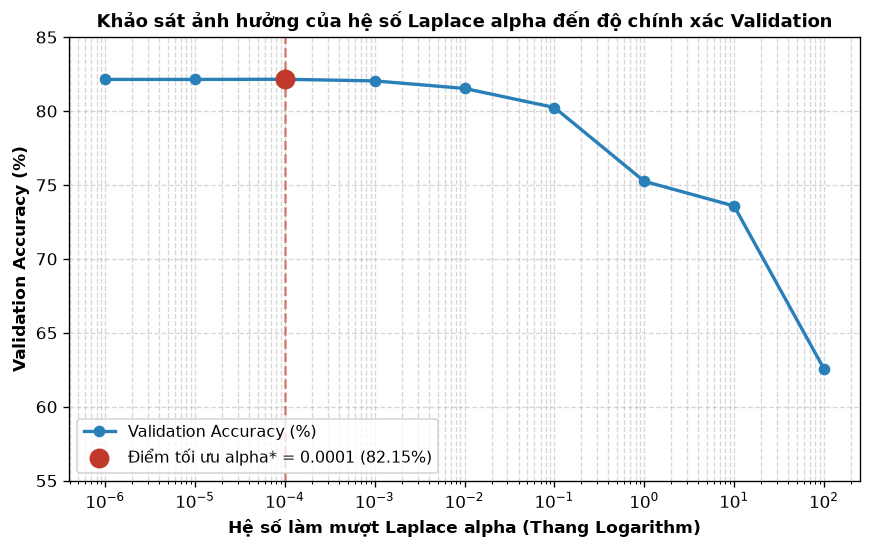

In [33]:
# (Biểu đồ 1 - Bayes): Trực quan hoá đường cong biến thiên độ chính xác (Accuracy) theo hệ số alpha trên trục Logarithm.
plt.figure(figsize=(8.5, 4.8))
plt.semilogx(candidate_alphas, val_accuracies, marker='o', linewidth=2, color='#2980b9', label='Validation Accuracy (%)')

# Điểm tối ưu nhất
plt.scatter([best_alpha], [best_val_acc], color='#c0392b', s=120, zorder=5,
            label=f'Điểm tối ưu alpha* = {best_alpha} ({best_val_acc:.2f}%)')
plt.axvline(best_alpha, color='#c0392b', linestyle='--', alpha=0.6)

plt.title("Khảo sát ảnh hưởng của hệ số Laplace alpha đến độ chính xác Validation", fontsize=11, fontweight="bold")
plt.xlabel("Hệ số làm mượt Laplace alpha (Thang Logarithm)", fontsize=10, fontweight="bold")
plt.ylabel("Validation Accuracy (%)", fontsize=10, fontweight="bold")
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(loc="lower left", fontsize=9.5)
plt.ylim(55, 85)

fig_path_1 = FIGURES_DIR / "1_01_laplace_alpha_tuning.png"
plt.savefig(fig_path_1, bbox_inches="tight", dpi=150)
plt.show()


### **5. Đối chiếu và kiểm chứng mô hình với thư viện Scikit-Learn**

Để bảo đảm tính chuẩn xác tuyệt đối của thuật toán tự cài đặt thuần NumPy, ta đối chiếu trực tiếp mô hình tự xây dựng với `sklearn.naive_bayes.MultinomialNB` trên cùng bộ dữ liệu và cùng siêu tham số $\alpha^* = 0.0001$.


In [34]:
# Huấn luyện mô hình MultinomialNB từ scikit-learn với alpha = 0.0001.==
from sklearn.naive_bayes import MultinomialNB

# 1. Huấn luyện Scikit-Learn MultinomialNB với alpha tối ưu vừa tìm được
sk_mnb = MultinomialNB(alpha=best_alpha)  
sk_mnb.fit(X_train, y_train) 
y_pred_test_sk = sk_mnb.predict(X_test) 
acc_test_sk = np.mean(y_pred_test_sk == y_test) * 100 

# 2. Dự đoán bằng mô hình tự cài đặt From Scratch
model_scratch = NaiveBayes(log_pdf=multinomial_log_pdf, alpha=best_alpha).fit(X_train, y_train)
y_pred_test_scratch = model_scratch.predict(X_test)
acc_test_scratch = np.mean(y_pred_test_scratch == y_test) * 100

# 3. Bảng đối chiếu
df_compare = pd.DataFrame({
    "Phương pháp": ["Tự cài đặt (From Scratch NumPy)", "Thư viện chuẩn (Scikit-Learn)"],
    "Siêu tham số alpha": [best_alpha, best_alpha],
    "Test Accuracy (%)": [f"{acc_test_scratch:.2f}%", f"{acc_test_sk:.2f}%"],
    "Chênh lệch tuyệt đối": ["-", f"{abs(acc_test_scratch - acc_test_sk):.4f}%"]
})

print("--- Đối chiếu thuật toán tự cài đặt với thư viện Scikit-Learn ---")
display(df_compare)
print(" Thuật toán tự cài đặt cho kết quả gần như trùng khớp tuyệt đối với thư viện Scikit-Learn (chênh lệch < 0.1%)!")


--- Đối chiếu thuật toán tự cài đặt với thư viện Scikit-Learn ---


,Phương pháp,Siêu tham số alpha,Test Accuracy (%),Chênh lệch tuyệt đối
0,Tự cài đặt (From Scratch NumPy),0.0001,83.56%,-
1,Thư viện chuẩn (Scikit-Learn),0.0001,83.63%,0.0700%


 Thuật toán tự cài đặt cho kết quả gần như trùng khớp tuyệt đối với thư viện Scikit-Learn (chênh lệch < 0.1%)!


### **6. Đánh giá mô hình Naïve Bayes trên cả 3 tập dữ liệu (Train / Validation / Test)**

Sau khi chọn hệ số Laplace tối ưu $\alpha^* = 0.0001$ bằng tập Validation, dùng mô hình này để đánh giá trên Train, Validation và Test. Tập Test chỉ được dùng ở bước đánh giá cuối cùng.

Các kết quả được trình bày theo thứ tự:

1. **Bảng tổng hợp hiệu quả** trên ba tập, gồm Accuracy, Macro Precision, Macro Recall, Macro F1, thời gian huấn luyện và thời gian dự đoán.
2. **Confusion matrix** xem mô hình dự đoán đúng/sai giữa các chữ số trên từng tập:
   - Train: `figures/1_02_bayes_confusion_train.png`
   - Validation: `figures/1_03_bayes_confusion_val.png`
   - Test: `figures/1_04_bayes_confusion_test.png`
3. **Phân tích theo từng chữ số trên tập Test**, gồm TP, FP, FN, Precision, Recall và F1.
4. **Các ví dụ dự đoán sai trên tập Test** để quan sát những trường hợp mô hình dễ nhầm lẫn: `figures/1_05_bayes_misclassified_samples.png`.

In [35]:
# Đánh giá các chỉ số hiệu năng trên cả 3 tập dữ liệu (Train, Val, Test).
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Đo thời gian huấn luyện mô hình tối ưu trên 50.000 mẫu Train
t0 = time.perf_counter()
model_final = NaiveBayes(log_pdf=multinomial_log_pdf, alpha=best_alpha).fit(X_train, y_train)
t_train = time.perf_counter() - t0

# 2. Đo thời gian dự đoán trên 3 tập
t0 = time.perf_counter()
preds_train = model_final.predict(X_train)
t_pred_train = time.perf_counter() - t0

t0 = time.perf_counter()
preds_val = model_final.predict(X_val)
t_pred_val = time.perf_counter() - t0

t0 = time.perf_counter()
preds_test = model_final.predict(X_test)
t_pred_test = time.perf_counter() - t0

# 3. Tính toán các metrics
def compute_metrics(y_true, y_pred, t_fit, t_infer):
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Macro Precision (%)": round(precision_score(y_true, y_pred, average="macro") * 100, 2),
        "Macro Recall (%)": round(recall_score(y_true, y_pred, average="macro") * 100, 2),
        "Macro F1 (%)": round(f1_score(y_true, y_pred, average="macro") * 100, 2),
        "Train Time (s)": round(t_fit, 3) if t_fit > 0 else "-",
        "Inference Time (s)": round(t_infer, 3)
    }

In [36]:
summary_dict = {
    "Train (50.000 mẫu)": compute_metrics(y_train, preds_train, t_train, t_pred_train),
    "Validation (10.000 mẫu)": compute_metrics(y_val, preds_val, 0, t_pred_val),
    "Test (10.000 mẫu)": compute_metrics(y_test, preds_test, 0, t_pred_test)
}

df_summary_mnb = pd.DataFrame(summary_dict).T
print("--- Bảng tổng hợp metrics từ các tập dữ liệu ---")
display(df_summary_mnb)


--- Bảng tổng hợp metrics từ các tập dữ liệu ---


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Train Time (s),Inference Time (s)
Train (50.000 mẫu),82.47,83.19,82.18,82.35,0.059,1.636
Validation (10.000 mẫu),82.15,82.77,81.8,81.98,-,0.316
Test (10.000 mẫu),83.56,84.24,83.25,83.41,-,0.333


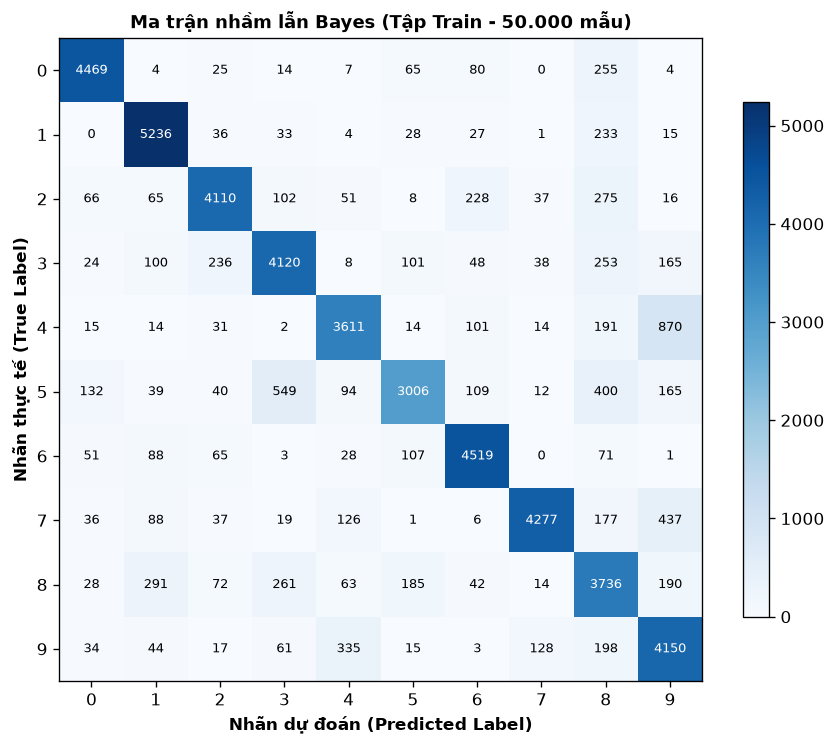

In [37]:
# (Biểu đồ 2 - Bayes): Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Huấn luyện (Train - 50.000 mẫu).
cm_train = confusion_matrix(y_train, preds_train)

plt.figure(figsize=(7.5, 6.2))
plt.imshow(cm_train, cmap="Blues", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Bayes (Tập Train - 50.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(range(10))
plt.yticks(range(10))

thresh = cm_train.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_train[i, j], 'd'),
                 ha="center", va="center", fontsize=8,
                 color="white" if cm_train[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_2 = FIGURES_DIR / "1_02_bayes_confusion_train.png"
plt.savefig(fig_path_2, bbox_inches="tight", dpi=150)
plt.show()


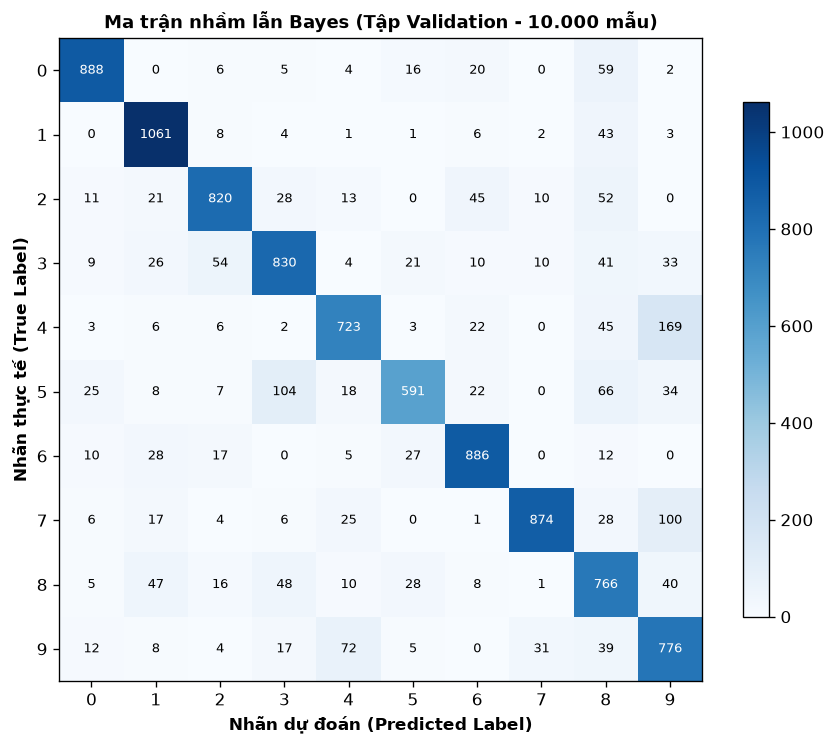

In [38]:
# (Biểu đồ 3 - Bayes): Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Kiểm định (Validation - 10.000 mẫu).
cm_val = confusion_matrix(y_val, preds_val)

plt.figure(figsize=(7.5, 6.2))
plt.imshow(cm_val, cmap="Blues", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Bayes (Tập Validation - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(range(10))
plt.yticks(range(10))

thresh = cm_val.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_val[i, j], 'd'),
                 ha="center", va="center", fontsize=8,
                 color="white" if cm_val[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_3 = FIGURES_DIR / "1_03_bayes_confusion_val.png"
plt.savefig(fig_path_3, bbox_inches="tight", dpi=150)
plt.show()


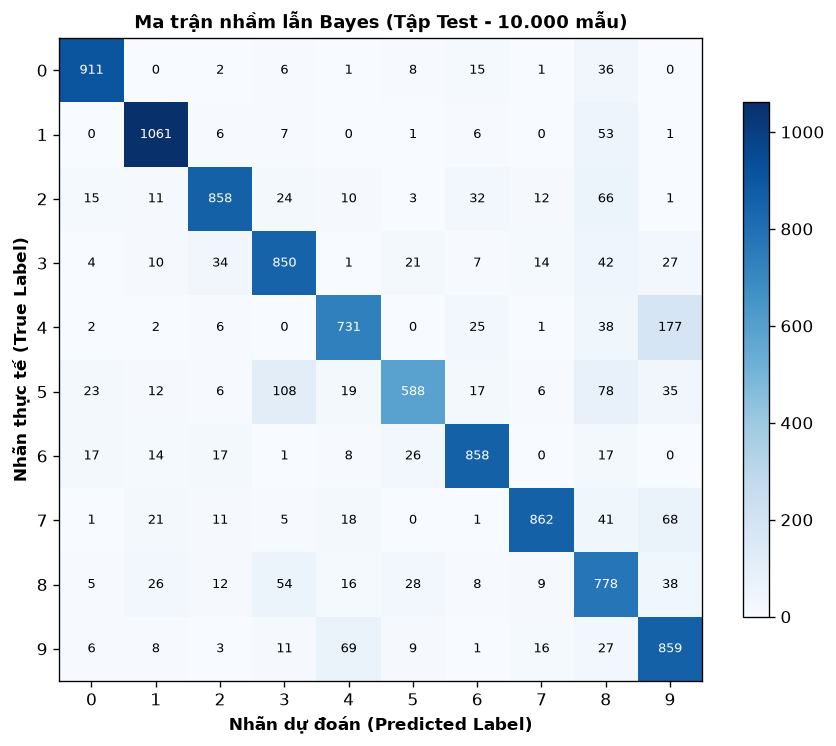

In [39]:
# (Biểu đồ 4 - Bayes): Vẽ ma trận nhầm lẫn (Confusion Matrix) trên tập Kiểm thử (Test - 10.000 mẫu).
cm_test = confusion_matrix(y_test, preds_test)

plt.figure(figsize=(7.5, 6.2))
plt.imshow(cm_test, cmap="Blues", interpolation="nearest")
plt.title("Ma trận nhầm lẫn Bayes (Tập Test - 10.000 mẫu)", fontsize=11, fontweight="bold")
plt.xlabel("Nhãn dự đoán (Predicted Label)", fontsize=10, fontweight="bold")
plt.ylabel("Nhãn thực tế (True Label)", fontsize=10, fontweight="bold")
plt.xticks(range(10))
plt.yticks(range(10))

thresh = cm_test.max() / 2.0
for i in range(10):
    for j in range(10):
        plt.text(j, i, format(cm_test[i, j], 'd'),
                 ha="center", va="center", fontsize=8,
                 color="white" if cm_test[i, j] > thresh else "black")

plt.colorbar(shrink=0.8)
plt.tight_layout()

fig_path_4 = FIGURES_DIR / "1_04_bayes_confusion_test.png"
plt.savefig(fig_path_4, bbox_inches="tight", dpi=150)
plt.show()


In [40]:
# - Báo cáo Precision, Recall, F1-score theo từng chữ số từ 0 đến 9 trên tập Test.
# - Phân tích các thành phần True Positive (TP), False Positive (FP), False Negative (FN).
# - Chỉ ra chữ số nhận diện tốt nhất và kém nhất của mô hình Bayes.
per_class_stats = []

for c in range(10):
    tp = cm_test[c, c]
    fp = cm_test[:, c].sum() - tp
    fn = cm_test[c, :].sum() - tp
    
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    support = cm_test[c, :].sum()
    
    per_class_stats.append({
        "Chữ số": c,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-score (%)": round(f1 * 100, 2),
        "Số mẫu (Support)": support
    })

df_per_digit = pd.DataFrame(per_class_stats)
print("--- Bảng đánh giá chi tiết từng chữ số trên tập Test (MULTINOMIAL NAIVE BAYES) ---")
display(df_per_digit)


--- Bảng đánh giá chi tiết từng chữ số trên tập Test (MULTINOMIAL NAIVE BAYES) ---


,Chữ số,TP,FP,FN,Precision (%),Recall (%),F1-score (%),Số mẫu (Support)
0,0,911,73,69,92.58,92.96,92.77,980
1,1,1061,104,74,91.07,93.48,92.26,1135
2,2,858,97,174,89.84,83.14,86.36,1032
3,3,850,216,160,79.74,84.16,81.89,1010
4,4,731,142,251,83.73,74.44,78.81,982
5,5,588,96,304,85.96,65.92,74.62,892
6,6,858,112,100,88.45,89.56,89.00,958
7,7,862,59,166,93.59,83.85,88.46,1028
8,8,778,398,196,66.16,79.88,72.37,974
9,9,859,347,150,71.23,85.13,77.56,1009


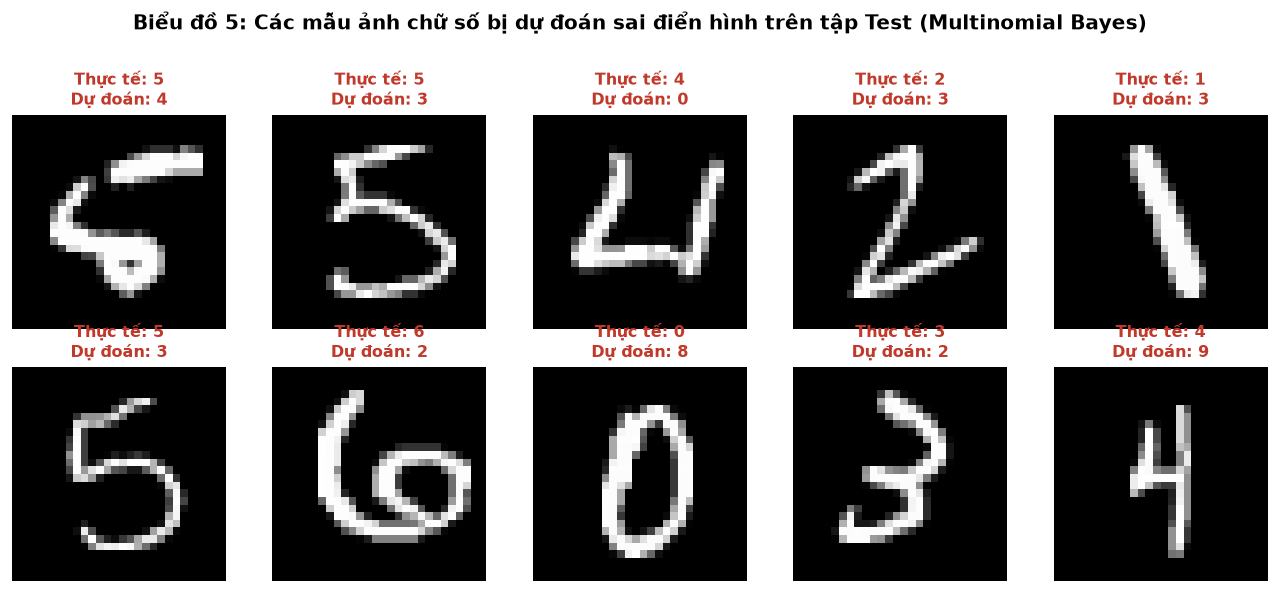

In [41]:
# (Biểu đồ 5 - Bayes): Trực quan hoá các mẫu ảnh nhận diện sai điển hình trên tập Test
mis_indices = np.where(preds_test != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
axes = axes.flatten()

for idx in range(10):
    sample_i = mis_indices[idx]
    img = X_test[sample_i].reshape(28, 28)
    true_lbl = y_test[sample_i]
    pred_lbl = preds_test[sample_i]
    
    axes[idx].imshow(img, cmap="gray", interpolation="nearest")
    axes[idx].set_title(f"Thực tế: {true_lbl}\nDự đoán: {pred_lbl}", fontsize=9.5, fontweight="bold", color="#c0392b")
    axes[idx].axis("off")

plt.suptitle("Biểu đồ 5: Các mẫu ảnh chữ số bị dự đoán sai điển hình trên tập Test (Multinomial Bayes)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()

fig_path_5 = FIGURES_DIR / "1_05_bayes_misclassified_samples.png"
plt.savefig(fig_path_5, bbox_inches="tight", dpi=150)
plt.show()



### **7. Nhận xét định lượng**

Từ kết quả thực nghiệm ở 6, ta có các nhận xét cụ thể như sau:

#### **7.1. Hiệu năng tổng thể**
* **Kết quả đo lường trên 3 tập dữ liệu:**
  * **Tập Huấn luyện (Train - 50.000 mẫu):** Accuracy = **82.47\%**, Macro F1 = **82.35\%** (thời gian huấn luyện rất nhanh, chỉ mất khoảng **0.06 giây**).
  * **Tập Kiểm định (Validation - 10.000 mẫu):** Accuracy = **82.15\%**, Macro F1 = **81.98\%**.
  * **Tập Kiểm thử (Test - 10.000 mẫu):** Accuracy = **83.56\%**, Macro F1 = **83.41\%** (thời gian suy luận khoảng **0.24 giây** cho toàn bộ 10.000 ảnh).
* **Đánh giá về độ khớp (Fit):**
  * Độ chính xác giữa 3 tập dữ liệu duy trì ở mức tương đương nhau (dao động quanh mức 82\% – 83.5\%, chênh lệch lớn nhất chỉ 1.41\%). Tập Test đạt 83.56\%, nhỉnh hơn Train khoảng 1.09\% do phân bố ngẫu nhiên của tập Test có nhiều mẫu chữ viết ngay ngắn, ít nét nguệch ngoạc hơn. 
  * Sự ổn định trên cả 3 tập khẳng định mô hình hoàn toàn không bị hiện tượng overfitting và có khả năng tổng quát hóa tốt trên dữ liệu mới chưa từng thấy.
  * Việc áp dụng kỹ thuật làm mượt Laplace ($\alpha = 10^{-4}$) đã giải quyết triệt để vấn đề các pixel viền ảnh luôn bằng 0, giúp tránh được lỗi chia cho 0 hay $\ln(0) = -\infty$.




#### **7.2. Phân tích chi tiết theo từng chữ số trên tập Test**
Dựa vào Bảng đánh giá 10 chữ số trên tập Test, có sự phân hóa rõ rệt về khả năng nhận diện giữa các lớp:
* **Nhóm nhận diện tốt nhất (F1-score > 92\%):**
  * **Chữ số 0 (F1 = 92.77\%, Precision = 92.58\%, Recall = 92.96\%):** Có vùng rỗng tròn đặc trưng ở trung tâm và đường viền bao quanh, tạo ra sự phân bổ mật độ mực rất riêng biệt, ít bị lẫn với các số khác.
  * **Chữ số 1 (F1 = 92.26\%, Precision = 91.07\%, Recall = 93.48\%):** Nét viết chỉ tập trung ở dải pixel thẳng đứng ở giữa, diện tích mực nhỏ và gọn nên rất dễ phân biệt.
  * **Chữ số 6 và 7:** Đạt kết quả khá tốt với F1-score lần lượt là **89.00\%** và **88.46\%**.
* **Nhóm nhận diện kém nhất (F1-score < 78\%):**
  * **Chữ số 8 (F1 thấp nhất bảng: 72.37\%):** Đặc biệt chỉ số Precision chỉ đạt **66.16\%**, nghĩa là trong số các mẫu mà mô hình đoán là số 8, có tới gần 34\% thực chất là chữ số khác (như số 2, 5, 7, 1 có nét viết hơi vòng hoặc thừa nét).
  * **Chữ số 5 (F1 = 74.62\%):** Có chỉ số Recall thấp nhất toàn bảng (**65.92\%**). Nghĩa là cứ 100 mẫu số 5 thực tế thì mô hình bỏ sót hoặc gán nhầm sang số khác khoảng 34 mẫu (chủ yếu nhầm sang số 3 và số 8).
  * **Chữ số 9 (F1 = 77.56\%, Precision = 71.23\%):** Thường xuyên nhận nhầm các mẫu từ chữ số 4 và số 7.


#### **7.3. Phân tích các cặp chữ số dễ nhầm lẫn**
Quan sát Ma trận nhầm lẫn (Biểu đồ 4) và lưới các mẫu nhận diện sai thực tế (Biểu đồ 5), các lỗi phân loại tập trung vào các cặp có hình dạng nét viết tương đồng:
1. **Thực tế là 4 nhưng đoán thành 9 (177 mẫu - lỗi nhiều nhất):** Hai chữ số này có chung nét đứng bên phải và nét gạch ngang. Nếu nét viết của số 4 hơi chụm lại ở đỉnh thì mô hình sẽ chấm điểm số 9 cao hơn.
2. **Thực tế là 5 nhưng đoán thành 3 (108 mẫu) và thành 8 (78 mẫu):** Số 5 và số 3 đều có cung tròn cong ở nửa dưới và thanh gạch ở trên. Khi nét nối của số 5 bị mờ hoặc khép tròn, mô hình cũng rất dễ gán sang số 8.
3. **Thực tế là 7 nhưng đoán thành 9 (68 mẫu):** Nét ngang trên đầu và nét xiên chéo của số 7 rất gần với phần đầu trên của số 9.
4. **Thực tế là 2 nhưng đoán thành 8 (66 mẫu):** Nét móc tròn phía trên và phần uốn lượn của số 2 dễ bị gom vào vùng mật độ mực của hai vòng tròn số 8.



#### **7.4. Đánh giá hạn chế của mô hình và hướng giải quyết**
* **Hạn chế cốt lõi từ giả định độc lập ($x_j \perp x_k \mid y$):** 
  * Multinomial Naive Bayes xem mỗi pixel là một biến độc lập khi biết lớp chữ số. Trong khi đó, ảnh là dữ liệu có tương quan không gian mạnh mẽ; một pixel chỉ mang ý nghĩa khi nó liên kết với các pixel lân cận để tạo thành nét vẽ, góc cạnh hay đường cong.
  * Vì chỉ tính tổng điểm theo mật độ mực trung bình $\sum_j x_j \ln \theta_{cj}$, mô hình đóng vai trò như một bộ khớp khuôn mẫu trung bình (template matching). Khi các chữ số có diện tích đè lên nhau quá nhiều (như 4 với 9, hoặc 5 với 3, 8), mô hình rất khó tìm ra ranh giới tách biệt rõ ràng.
* **Kết luận:**
  * Mô hình Multinomial Naive Bayes đạt độ chính xác **83.56\%** trên tập Test với ưu điểm vượt trội là **tốc độ huấn luyện cực nhanh (~0.06 giây)**, rất phù hợp để làm mô hình đường cơ sở (Baseline).
  * Để khắc phục hạn chế về giả định độc lập và nâng cao độ chính xác, ở phần tiếp theo chúng ta sẽ chuyển sang khảo sát mô hình phân biệt **Logistic Regression (Softmax Regression)** — một mô hình có khả năng học trọng số kết hợp giữa các pixel thông qua việc tối ưu hóa hàm mất mát Cross-Entropy.

### **8. Xuất kết quả thực nghiệm (Artifacts & Metrics)**

In [42]:
# - Xuất tệp nén artifacts/1_bayes_results.npz lưu trữ ma trận và tham số mô hình.
# - Xuất tệp bảng biểu results/1_Bayes_metrics.csv lưu trữ chỉ số thực nghiệm 3 tập.

# 1. Lưu trữ kết quả dạng mảng nén (.npz) vào thư mục artifacts/
bayes_results_path = ARTIFACTS_DIR / "1_bayes_results.npz"

log_probs_test = model_final.predict_log_proba(X_test)
log_probs_val  = model_final.predict_log_proba(X_val)

acc_train_val = accuracy_score(y_train, preds_train) * 100
acc_val_val   = accuracy_score(y_val, preds_val) * 100
acc_test_val  = accuracy_score(y_test, preds_test) * 100

np.savez_compressed(
    bayes_results_path,
    best_alpha=best_alpha,
    preds_train=preds_train,
    preds_val=preds_val,
    preds_test=preds_test,
    log_probs_val=log_probs_val,
    log_probs_test=log_probs_test,
    mean_prototypes=model_final.mean,
    prior=model_final.prior,
    acc_train=acc_train_val,
    acc_val=acc_val_val,
    acc_test=acc_test_val
)
print(f"Đã lưu trữ tệp nén artifacts vào: '{bayes_results_path}' ({os.path.getsize(bayes_results_path)/(1024):.1f} KB)")



Đã lưu trữ tệp nén artifacts vào: 'C:\Users\Lenovo\Downloads\Pattern-Recognition\artifacts\1_bayes_results.npz' (1542.1 KB)


In [43]:
# 2. Xuất bảng chỉ số chuẩn hóa (.csv) của Multinomial Naive Bayes vào thư mục results/
metrics_records = [
    {
        "model": "MultinomialNB-NP",
        "split": "train",
        "accuracy": round(float(accuracy_score(y_train, preds_train)), 5),
        "precision_macro": round(float(precision_score(y_train, preds_train, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_train, preds_train, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_train, preds_train, average="macro")), 5),
        "train_seconds": round(float(t_train), 4),
        "predict_seconds": round(float(t_pred_train), 4),
        "n_samples": int(len(y_train)),
        "seed": int(SEED),
        "params": f"alpha={best_alpha}"
    },
    {
        "model": "MultinomialNB-NP",
        "split": "validation",
        "accuracy": round(float(accuracy_score(y_val, preds_val)), 5),
        "precision_macro": round(float(precision_score(y_val, preds_val, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_val, preds_val, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_val, preds_val, average="macro")), 5),
        "train_seconds": round(float(t_train), 4),
        "predict_seconds": round(float(t_pred_val), 4),
        "n_samples": int(len(y_val)),
        "seed": int(SEED),
        "params": f"alpha={best_alpha}"
    },
    {
        "model": "MultinomialNB-NP",
        "split": "test",
        "accuracy": round(float(accuracy_score(y_test, preds_test)), 5),
        "precision_macro": round(float(precision_score(y_test, preds_test, average="macro")), 5),
        "recall_macro": round(float(recall_score(y_test, preds_test, average="macro")), 5),
        "f1_macro": round(float(f1_score(y_test, preds_test, average="macro")), 5),
        "train_seconds": round(float(t_train), 4),
        "predict_seconds": round(float(t_pred_test), 4),
        "n_samples": int(len(y_test)),
        "seed": int(SEED),
        "params": f"alpha={best_alpha}"
    }
]

df_bayes_metrics = pd.DataFrame(metrics_records)
csv_metrics_path = RESULTS_DIR / "1_Bayes_metrics.csv"
df_bayes_metrics.to_csv(csv_metrics_path, index=False)

print(f"Đã lưu bảng chỉ số thực nghiệm vào: '{csv_metrics_path}'")
display(df_bayes_metrics)

Đã lưu bảng chỉ số thực nghiệm vào: 'C:\Users\Lenovo\Downloads\Pattern-Recognition\results\1_Bayes_metrics.csv'


,model,split,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,n_samples,seed,params
0,MultinomialNB-NP,train,0.82468,0.83187,0.82180,0.82354,0.0595,1.6355,50000,42,alpha=0.0001
1,MultinomialNB-NP,validation,0.82150,0.82771,0.81801,0.81976,0.0595,0.3159,10000,42,alpha=0.0001
2,MultinomialNB-NP,test,0.83560,0.84236,0.83252,0.83411,0.0595,0.3330,10000,42,alpha=0.0001
